In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import scipy 


def simulation_wrapper(state0, params, update, sim_time, dt): 
    #euler method to see behaviour quickly
    
    states = np.zeros([int(sim_time/dt)+1, state0.shape[0], state0.shape[1]])
    states[0] = state0
    
    for t in range(int(sim_time/dt)): 
        states[t+1] = update(params, states[t], dt)
        
    return states[1:]

rng = np.random.RandomState(seed = 5)

#set parameters between models
N = 2 #number of genes/mRNA with differeng length

#we sample the length here, so we can compare all models directly without having to average
l_mean = 1 #mean of length of the genes
l_sd = 1.
l_alpha = (l_mean/l_sd)**2 # parameters for gamma distribution
l_theta = l_sd**2/l_mean # parameters for gamma distribution
l = np.sort(rng.gamma(l_alpha,scale = l_theta,size = N)) #length of the mRNA chain

α_mean = 0.05
# α_sd = 0.2
α_rand = rng.randn(N)

β_mean = 5
β_sd = β_mean
β_alpha = (β_mean/β_sd)**2 # parameters for gamma distribution
β_theta = β_sd**2/β_mean # parameters for gamma distribution
β_rand = rng.randn(N) 

γ_mean = .3
γ_sd = 0.0001
γ_rand = rng.randn(N)

x0_mean = 1
x0_sd = 0.001
x0 = x0_mean + x0_sd*np.random.randn(N)


In [2]:
def prop_init_model(parameters, state_var, dt ):
    #parmeters are: 
    #alpha, beta, and gamma (initation, elongation, degradation) rate and R (numer of total ribosomes)
    
    #parameters is a dictionary with the different parameters 
    #we just read them out below to return the updated amounts of interactions
    
    x_vec = state_var[0]   #free mRNA concentrations
    xr_vec = state_var[1]  # bound mRNA ribosome concentrations
    y_vec = state_var[2]   #protein concentrations
    y_free = parameters['Y_max'] - np.sum(y_vec)  #concentration of free proteins
    r = parameters['R'] - np.sum(xr_vec)  #concentration of free ribosomes - no_synthesis

    new_x_vec = x_vec + dt * (-parameters['α']  * y_free * r * x_vec  + parameters['β'] * xr_vec)
    new_xr_vec = xr_vec + dt * (parameters['α'] * r * y_free *  x_vec - parameters['β'] * xr_vec)
    new_y_vec = y_vec + dt * ( parameters['β'] * xr_vec - parameters['γ'] * y_vec)

    return new_x_vec, new_xr_vec, new_y_vec


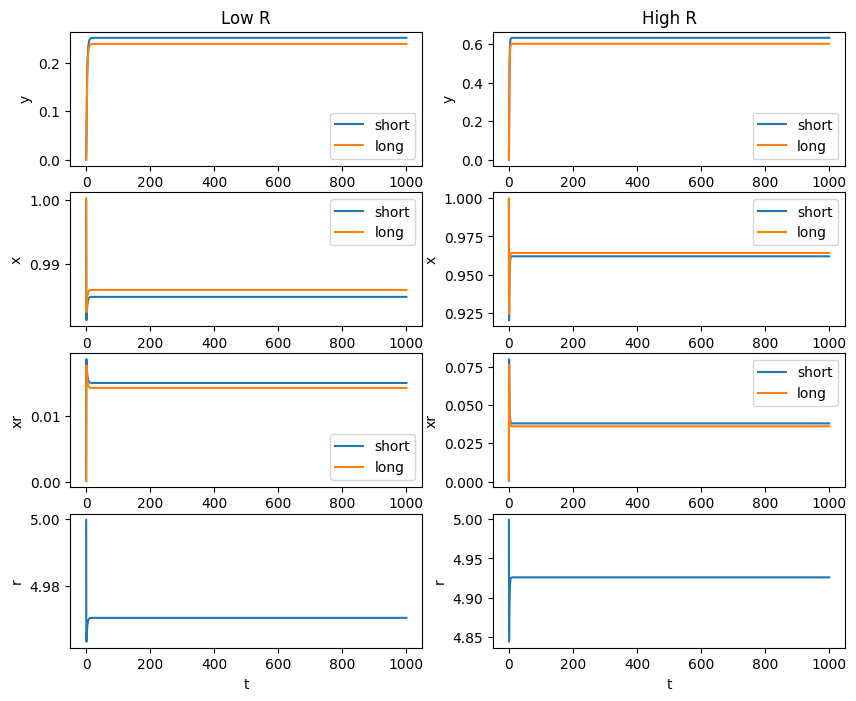

Ratio (short/long) in low condition:1.0528796852721933
Ratio (short/long) in high condition:1.051640027332787


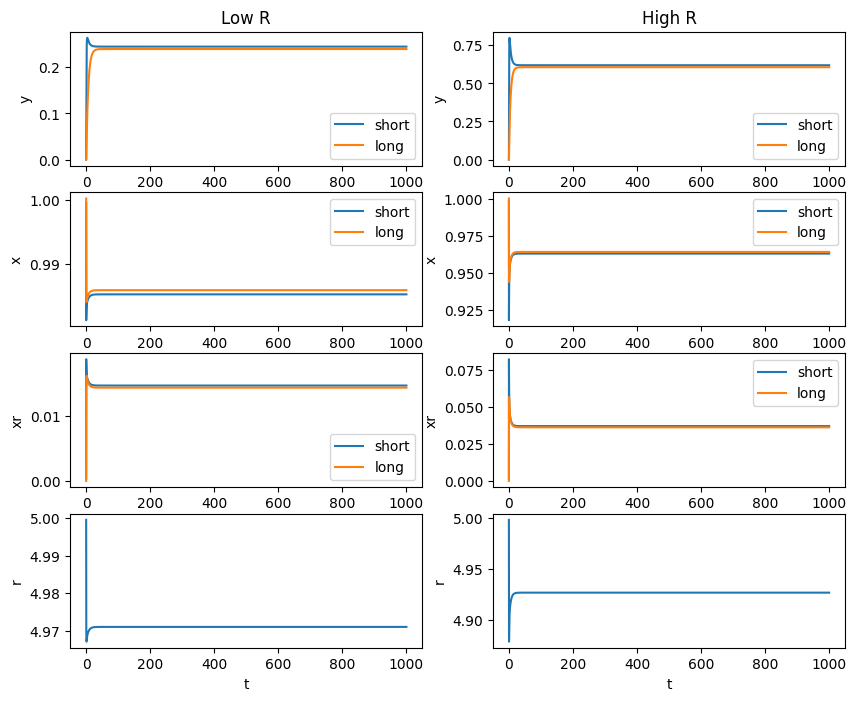

Ratio (short/long) in low condition:1.0217438501220184
Ratio (short/long) in high condition:1.021218204770249


In [3]:
####no length dependency
# calculate parameters  
α = α_mean  + 0.001* α_rand
β = β_mean  + 0.001* β_rand
γ = γ_mean  + γ_sd* γ_rand



parameters = dict()
parameters['α'] = α
parameters['β'] = β
parameters['γ'] = γ
parameters['l'] = l
parameters['R'] = 1
parameters['Y_max'] = N

#init_state =np.array([x0, np.zeros([N]), (Y_max/N)*np.ones([N]), parameters['Y_max']*np.ones([N])])#[x0; zeros(N); (Y_max/N)*ones(N); zeros(N)]
init_state =np.array([x0, np.zeros([N]),np.zeros([N])]) 
sim_time = 1000
dt = 0.001

baseline_low = simulation_wrapper(init_state,parameters, prop_init_model, sim_time, dt) 


parameters['R'] = 5
baseline_high = simulation_wrapper(init_state,parameters, prop_init_model, sim_time, dt) 

fig, ax = plt.subplots(4,2,figsize = (10,8))
ax[0,0].plot(np.arange(0,sim_time,dt), baseline_low[:,2,0], label = 'short')
ax[0,0].plot(np.arange(0,sim_time,dt), baseline_low[:,2,1], label = 'long')
ax[0,0].set_ylabel('y')
ax[0,0].set_xlabel('t')
ax[0,0].legend()
ax[1,0].plot(np.arange(0,sim_time,dt), baseline_low[:,0,0], label = 'short')
ax[1,0].plot(np.arange(0,sim_time,dt), baseline_low[:,0,1], label = 'long')
ax[1,0].set_ylabel('x')
ax[1,0].set_xlabel('t')
ax[1,0].legend()
ax[2,0].plot(np.arange(0,sim_time,dt), baseline_low[:,1,0], label = 'short')
ax[2,0].plot(np.arange(0,sim_time,dt), baseline_low[:,1,1], label = 'long')
ax[2,0].set_ylabel('xr')
ax[2,0].set_xlabel('t')
ax[2,0].legend()
ax[3,0].plot(np.arange(0,sim_time,dt), parameters['R']-np.sum(baseline_low[:,1,:], axis = 1))
ax[3,0].set_ylabel('r')
ax[3,0].set_xlabel('t')

ax[0,1].plot(np.arange(0,sim_time,dt), baseline_high[:,2,0], label = 'short')
ax[0,1].plot(np.arange(0,sim_time,dt), baseline_high[:,2,1], label = 'long')
ax[0,1].set_ylabel('y')
ax[0,1].set_xlabel('t')
ax[0,1].legend()
ax[1,1].plot(np.arange(0,sim_time,dt), baseline_high[:,0,0], label = 'short')
ax[1,1].plot(np.arange(0,sim_time,dt), baseline_high[:,0,1], label = 'long')
ax[1,1].set_ylabel('x')
ax[1,1].set_xlabel('t')
ax[1,1].legend()
ax[2,1].plot(np.arange(0,sim_time,dt), baseline_high[:,1,0], label = 'short')
ax[2,1].plot(np.arange(0,sim_time,dt), baseline_high[:,1,1], label = 'long')
ax[2,1].set_ylabel('xr')
ax[2,1].set_xlabel('t')
ax[2,1].legend()
ax[3,1].plot(np.arange(0,sim_time,dt), parameters['R']-np.sum(baseline_high[:,1,:], axis = 1))
ax[3,1].set_ylabel('r')
ax[3,1].set_xlabel('t')
ax[0,0].set_title('Low R')
ax[0,1].set_title('High R')
plt.show()

print('Ratio (short/long) in low condition:'+str(baseline_low[-1,2,0]/baseline_low[-1,2,1]) )
print('Ratio (short/long) in high condition:'+str(baseline_high[-1,2,0]/baseline_high[-1,2,1]) )




#########length dependency

# calculate parameters  
α = α_mean / l + 0.001* α_rand  #check that these are the correct proportionality assumptions
β = β_mean / l + 0.001* β_rand
γ = γ_mean / l + γ_sd* γ_rand



parameters = dict()
parameters['α'] = α
parameters['β'] = β
parameters['γ'] = γ
parameters['l'] = l
parameters['R'] = 1
parameters['Y_max'] = N

#init_state =np.array([x0, np.zeros([N]), (Y_max/N)*np.ones([N]), parameters['Y_max']*np.ones([N])])#[x0; zeros(N); (Y_max/N)*ones(N); zeros(N)]
init_state =np.array([x0, np.zeros([N]),np.zeros([N])]) 
sim_time = 1000
dt = 0.001

baseline_low = simulation_wrapper(init_state,parameters, prop_init_model, sim_time, dt) 


parameters['R'] = 5
baseline_high = simulation_wrapper(init_state,parameters, prop_init_model, sim_time, dt) 

fig, ax = plt.subplots(4,2,figsize = (10,8))
ax[0,0].plot(np.arange(0,sim_time,dt), baseline_low[:,2,0], label = 'short')
ax[0,0].plot(np.arange(0,sim_time,dt), baseline_low[:,2,1], label = 'long')
ax[0,0].set_ylabel('y')
ax[0,0].set_xlabel('t')
ax[0,0].legend()
ax[1,0].plot(np.arange(0,sim_time,dt), baseline_low[:,0,0], label = 'short')
ax[1,0].plot(np.arange(0,sim_time,dt), baseline_low[:,0,1], label = 'long')
ax[1,0].set_ylabel('x')
ax[1,0].set_xlabel('t')
ax[1,0].legend()
ax[2,0].plot(np.arange(0,sim_time,dt), baseline_low[:,1,0], label = 'short')
ax[2,0].plot(np.arange(0,sim_time,dt), baseline_low[:,1,1], label = 'long')
ax[2,0].set_ylabel('xr')
ax[2,0].set_xlabel('t')
ax[2,0].legend()
ax[3,0].plot(np.arange(0,sim_time,dt), parameters['R']-np.sum(baseline_low[:,1,:], axis = 1))
ax[3,0].set_ylabel('r')
ax[3,0].set_xlabel('t')

ax[0,1].plot(np.arange(0,sim_time,dt), baseline_high[:,2,0], label = 'short')
ax[0,1].plot(np.arange(0,sim_time,dt), baseline_high[:,2,1], label = 'long')
ax[0,1].set_ylabel('y')
ax[0,1].set_xlabel('t')
ax[0,1].legend()
ax[1,1].plot(np.arange(0,sim_time,dt), baseline_high[:,0,0], label = 'short')
ax[1,1].plot(np.arange(0,sim_time,dt), baseline_high[:,0,1], label = 'long')
ax[1,1].set_ylabel('x')
ax[1,1].set_xlabel('t')
ax[1,1].legend()
ax[2,1].plot(np.arange(0,sim_time,dt), baseline_high[:,1,0], label = 'short')
ax[2,1].plot(np.arange(0,sim_time,dt), baseline_high[:,1,1], label = 'long')
ax[2,1].set_ylabel('xr')
ax[2,1].set_xlabel('t')
ax[2,1].legend()
ax[3,1].plot(np.arange(0,sim_time,dt), parameters['R']-np.sum(baseline_high[:,1,:], axis = 1))
ax[3,1].set_ylabel('r')
ax[3,1].set_xlabel('t')
ax[0,0].set_title('Low R')
ax[0,1].set_title('High R')
plt.show()

print('Ratio (short/long) in low condition:'+str(baseline_low[-1,2,0]/baseline_low[-1,2,1]) )
print('Ratio (short/long) in high condition:'+str(baseline_high[-1,2,0]/baseline_high[-1,2,1]) )

